# mzML Plotting Comparison: pyOpenMS vs. pyteomics

This notebook demonstrates how to extract and plot a specific mass spectrum from an `mzML` file using two different libraries: **pyOpenMS** and **pyteomics**.

The goal is to ensure that both methods yield identical results by keeping their loading and extraction logic completely independent.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pyopenms
from pyteomics import mzml as py_mzml

## Configuration
Set the path to your mzML file and the Target Spectrum ID (Native ID) you wish to plot.

In [7]:
# REPLACE THESE WITH YOUR ACTUAL FILE AND SPECTRUM ID
MZML_FILE_PATH = "/mnt/volume/nacho/data/ProCa_Anna/small_dataset/251201_AD_ProC_ImmProCure_Synpep_100fmoluL_LCV005-2_MSV035_HT_Slot1-1_1_9333.mzML"
TARGET_SPECTRUM_ID =  "index=70956" #"controllerType=0 controllerNumber=1 scan=100" # Example format

## Method 1: pyOpenMS
This function loads the file using `pyopenms.MSExperiment` and iterates to find the spectrum with the matching native ID.

In [8]:
def get_data_pyopenms(file_path, target_id):
    """
    Loads mzML, finds target spectrum (assumed MS2), and its precursor MS1.
    Returns a dict: {'MS1': (mz, int, id), 'MS2': (mz, int, id)}
    """
    print(f"[pyOpenMS] Loading {file_path}...")
    exp = pyopenms.MSExperiment()
    pyopenms.MzMLFile().load(file_path, exp)
    
    target_idx = -1
    # Find target index
    for i, spec in enumerate(exp):
        if spec.getNativeID() == target_id:
            target_idx = i
            break
            
    if target_idx == -1:
        raise ValueError(f"Spectrum {target_id} not found in PyOpenMS.")
        
    results = {}
    
    # Get Target Spectrum (MS2)
    target_spec = exp[target_idx]
    if target_spec.getMSLevel() == 2:
        mz, inte = target_spec.get_peaks()
        results['MS2'] = (mz, inte, target_spec.getNativeID())
        
        # Find preceding MS1
        for i in range(target_idx - 1, -1, -1):
            if exp[i].getMSLevel() == 1:
                mz1, inte1 = exp[i].get_peaks()
                results['MS1'] = (mz1, inte1, exp[i].getNativeID())
                break
    else:
        # Target is MS1
        mz, inte = target_spec.get_peaks()
        results['MS1'] = (mz, inte, target_spec.getNativeID())
        
    return results


## Method 2: pyteomics
This function loads the file using `pyteomics.mzml.read` and retrieves the spectrum by ID.

In [9]:
def get_data_pyteomics(file_path, target_id):
    """
    Loads via pyteomics, finds target MS2 and precursor MS1.
    Returns a dict: {'MS1': (mz, int, id), 'MS2': (mz, int, id)}
    """
    print(f"[pyteomics] Loading {file_path}...")
    results = {}
    
    with py_mzml.read(file_path, use_index=True) as reader:
        # Get target
        try:
            spec = reader.get_by_id(target_id)
        except KeyError:
             raise ValueError(f"Spectrum {target_id} not found in Pyteomics.")
             
        # Check MS level
        if spec['ms level'] == 2:
            results['MS2'] = (spec['m/z array'], spec['intensity array'], spec['id'])
            
            # Find precursor MS1
            # Scan index is available in 'index' attribute (0-based order stored by pyteomics indexing)
            # We can use reader[index-1] to search backwards if indexed
            # NOTE: reader.get_by_index or reader[i] access by 0-based index in file order
            if 'index' in spec:
                 current_idx = spec['index']
                 for i in range(current_idx - 1, -1, -1):
                     try:
                         prev_spec = reader[i]
                         if prev_spec['ms level'] == 1:
                             results['MS1'] = (prev_spec['m/z array'], prev_spec['intensity array'], prev_spec['id'])
                             break
                     except IndexError: 
                         break
        else:
            # Target is MS1
            results['MS1'] = (spec['m/z array'], spec['intensity array'], spec['id'])
            
    return results


## Comparison & Plotting
Now we run both methods and compare the results numerically and visually.

[pyOpenMS] Loading /mnt/volume/nacho/data/ProCa_Anna/small_dataset/251201_AD_ProC_ImmProCure_Synpep_100fmoluL_LCV005-2_MSV035_HT_Slot1-1_1_9333.mzML...
[pyteomics] Loading /mnt/volume/nacho/data/ProCa_Anna/small_dataset/251201_AD_ProC_ImmProCure_Synpep_100fmoluL_LCV005-2_MSV035_HT_Slot1-1_1_9333.mzML...
--- Comparison Results ---
MS1: MATCH | IDs: index=70955 vs index=70955
MS2: MATCH | IDs: index=70956 vs index=70956

--- Generating Plots ---


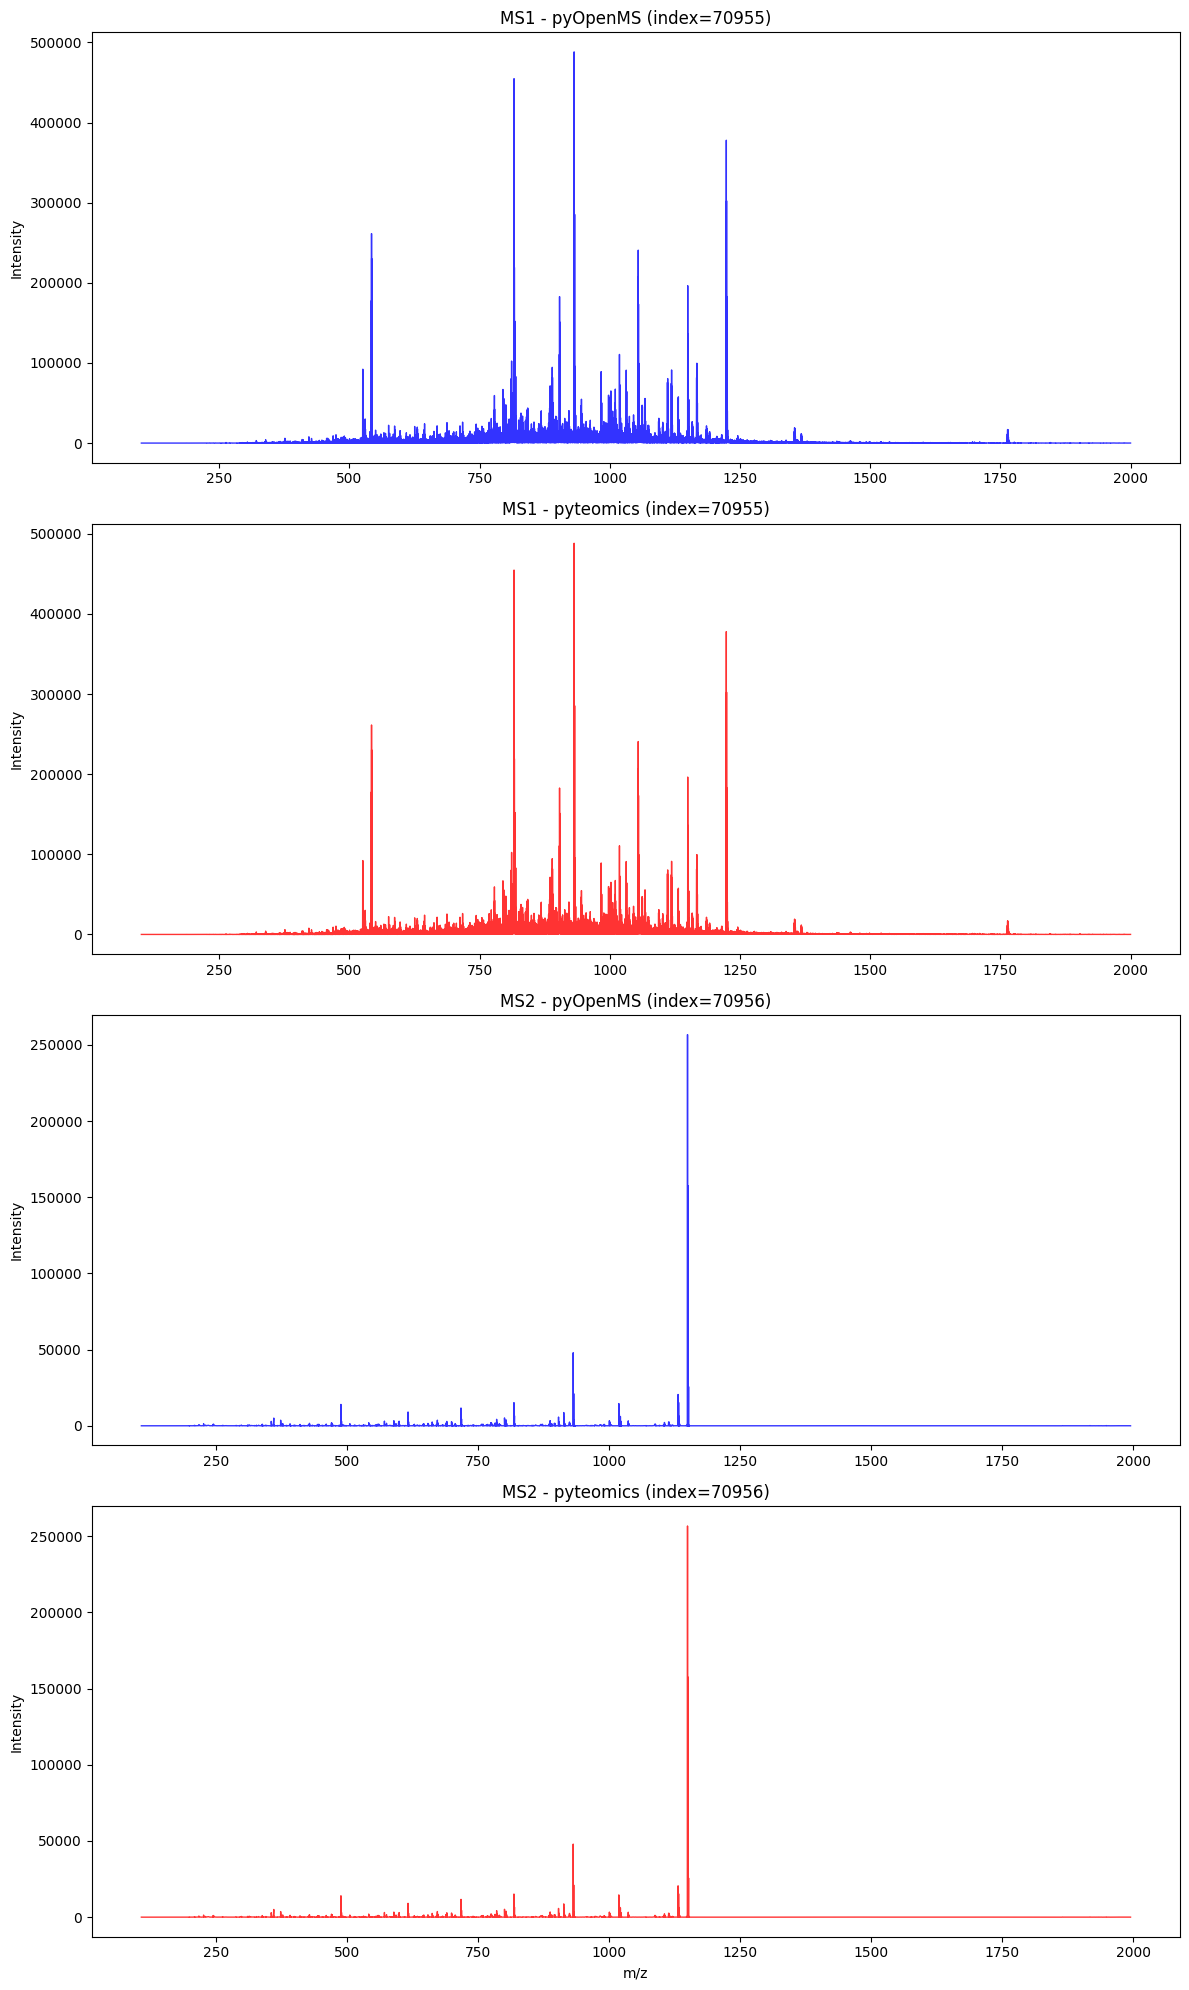

In [10]:
try:
    # 1. Run Extractions
    data_openms = get_data_pyopenms(MZML_FILE_PATH, TARGET_SPECTRUM_ID)
    data_pyteomics = get_data_pyteomics(MZML_FILE_PATH, TARGET_SPECTRUM_ID)
    
    # 2. Compare and Plot
    # Request: 4 plots per index (MS1 OpenMS, MS1 Pyteomics, MS2 OpenMS, MS2 Pyteomics)
    fig, ax = plt.subplots(4, 1, figsize=(12, 20))
    
    # Define the 4 plots we want to create
    plot_defs = [
        {'level': 'MS1', 'source': 'pyOpenMS', 'color': 'blue', 'data_dict': data_openms, 'idx': 0},
        {'level': 'MS1', 'source': 'pyteomics', 'color': 'red', 'data_dict': data_pyteomics, 'idx': 1},
        {'level': 'MS2', 'source': 'pyOpenMS', 'color': 'blue', 'data_dict': data_openms, 'idx': 2},
        {'level': 'MS2', 'source': 'pyteomics', 'color': 'red', 'data_dict': data_pyteomics, 'idx': 3},
    ]
    
    # First, print comparison
    print("--- Comparison Results ---")
    for level in ['MS1', 'MS2']:
        om_data = data_openms.get(level)
        py_data = data_pyteomics.get(level)
        
        if om_data and py_data:
            mz_om, int_om, id_om = om_data
            mz_py, int_py, id_py = py_data
            
            # Numerical check
            match_len = len(mz_om) == len(mz_py)
            match_val = False
            if match_len:
                match_val = np.allclose(mz_om, mz_py, atol=1e-4) and np.allclose(int_om, int_py, atol=1e-4)
            
            status = "MATCH" if match_len and match_val else f"MISMATCH (Len: {len(mz_om)} vs {len(mz_py)})"
            print(f"{level}: {status} | IDs: {id_om} vs {id_py}")
        else:
            print(f"{level}: Missing data in one or both sources.")

    print("\n--- Generating Plots ---")
    
    for p in plot_defs:
        i = p['idx']
        level = p['level']
        source = p['source']
        data = p['data_dict'].get(level)
        
        if data:
            mz, inte, sid = data
            ax[i].plot(mz, inte, color=p['color'], alpha=0.8, linewidth=1)
            ax[i].set_title(f"{level} - {source} ({sid})")
            ax[i].set_ylabel("Intensity")
            if i == 3: ax[i].set_xlabel("m/z")
        else:
            ax[i].text(0.5, 0.5, f"{level} {source}: Not Found", ha='center', va='center')
            ax[i].set_title(f"{level} - {source}: Not Found")
            
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()
